In [11]:
import sys
import os
import matplotlib.pyplot as plt

site_pkg = os.path.expanduser("~/miniforge3/lib/python3.13/site-packages")
if site_pkg in sys.path:
    sys.path.remove(site_pkg)
sys.path.insert(0, site_pkg)
from pathlib import Path
workspace = next(p for p in Path.cwd().resolve().parents if p.name.lower() == "selina")

import anndata as ad
import scanpy as sc
import numpy as np
# import scipy as sc 

# import scvi

# SYSA: synovial sarcoma (practice data)

In [12]:
adata = ad.read_h5ad(workspace/"data/scvi_sysa_feb26.h5ad")
adata

AnnData object with n_obs × n_vars = 112903 × 34876
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'cytetype_annotation_leiden', 'cytetype_cellOntologyTerm_leiden', 'cytetype_cellOntologyTermID_leiden', 'cytetype_cellState_leiden'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'gene_symbols'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'celltype_colors', 'cytetype_annotation_leiden_colors', 'cytetype_jobDetails', 'cytetype_results', 'leiden', 'log1p', 'neighbors', 'rank_genes_groups', 'rank_genes_leiden', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', 'scvi_normalized', None (.X)

In [13]:
adata.obs.head(5)

,pool,assignment,celltype,seurat_clusters,Cohort,Entity,Fusion,Episode,PID,Location,...,total_counts,total_counts_mt,pct_counts_mt,_scvi_batch,_scvi_labels,leiden,cytetype_annotation_leiden,cytetype_cellOntologyTerm_leiden,cytetype_cellOntologyTermID_leiden,cytetype_cellState_leiden
pool7_AAACAGCCACAACAAA-1,pool7,pool7-I015_014,Tumor,1.0,pediatric,SYSA,SS18::SSX1,relapse2,INF_R_2553,Soft tissue (paratracheal),...,3633.0,0.0,0.0,0,0,2,SS18::SSX1 fusion-positive synovial sarcoma - ...,mesenchymal cell,CL_0008019,Proliferating and metabolically reprogrammed
pool7_AAACAGCCATGGTTAT-1,pool7,pool7-I015_014,Tumor,1.0,pediatric,SYSA,SS18::SSX1,relapse2,INF_R_2553,Soft tissue (paratracheal),...,2858.0,0.0,0.0,0,0,1,Synovial sarcoma tumor cell - quiescent/ECM-re...,neoplastic cell,CL_0001063,Quiescent and ECM-remodeling
pool7_AAACATGCAAGCTACC-1,pool7,pool7-I015_014,Tumor,1.0,pediatric,SYSA,SS18::SSX1,relapse2,INF_R_2553,Soft tissue (paratracheal),...,4258.0,0.0,0.0,0,0,1,Synovial sarcoma tumor cell - quiescent/ECM-re...,neoplastic cell,CL_0001063,Quiescent and ECM-remodeling
pool7_AAACATGCACTGGCCA-1,pool7,pool7-I015_014,Tumor,1.0,pediatric,SYSA,SS18::SSX1,relapse2,INF_R_2553,Soft tissue (paratracheal),...,8584.0,0.0,0.0,0,0,0,Synovial sarcoma tumor cell - ECM-remodeling q...,neoplastic cell,CL_0001063,Quiescent and ECM-producing
pool7_AAACATGCATGTTGGC-1,pool7,pool7-I015_014,Tumor,1.0,pediatric,SYSA,SS18::SSX1,relapse2,INF_R_2553,Soft tissue (paratracheal),...,3466.0,0.0,0.0,0,0,2,SS18::SSX1 fusion-positive synovial sarcoma - ...,mesenchymal cell,CL_0008019,Proliferating and metabolically reprogrammed


In [14]:
print(adata.obs.shape)
print(adata.obs.columns)

(112903, 23)
Index(['pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity',
       'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes',
       'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt',
       '_scvi_batch', '_scvi_labels', 'leiden', 'cytetype_annotation_leiden',
       'cytetype_cellOntologyTerm_leiden',
       'cytetype_cellOntologyTermID_leiden', 'cytetype_cellState_leiden'],
      dtype='str')


## Umpas

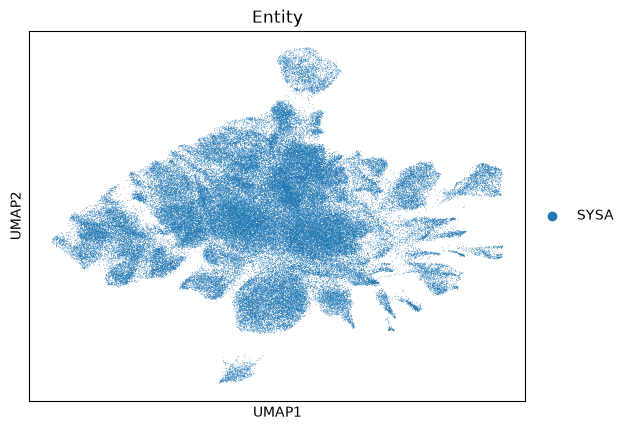

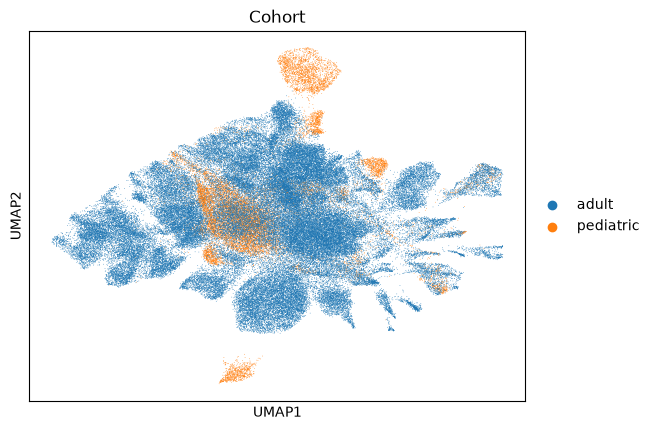

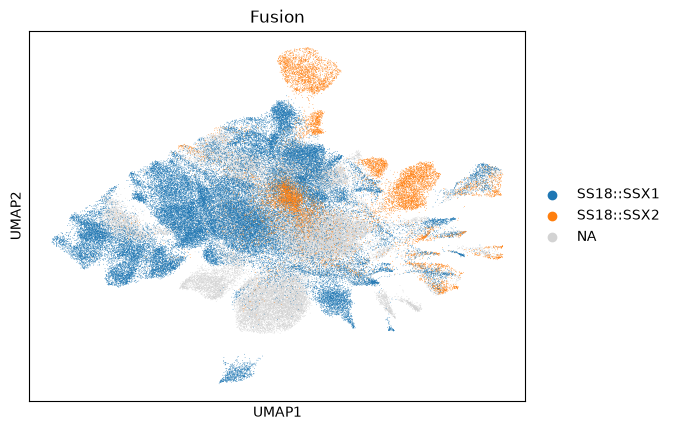

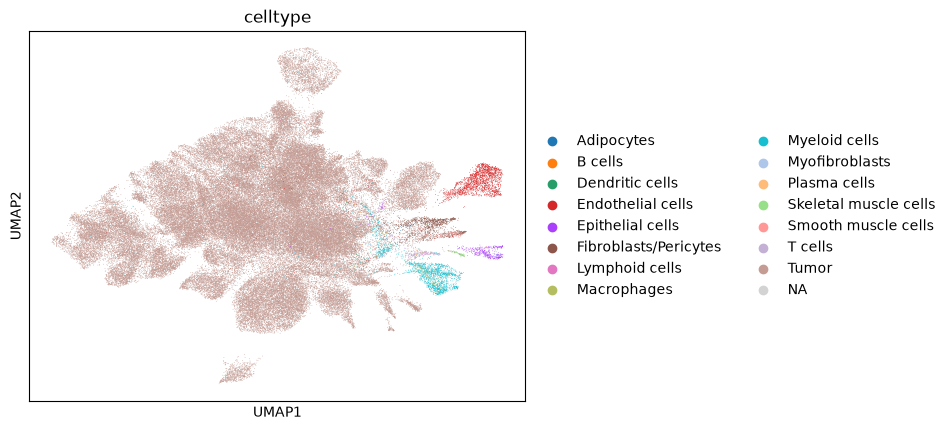

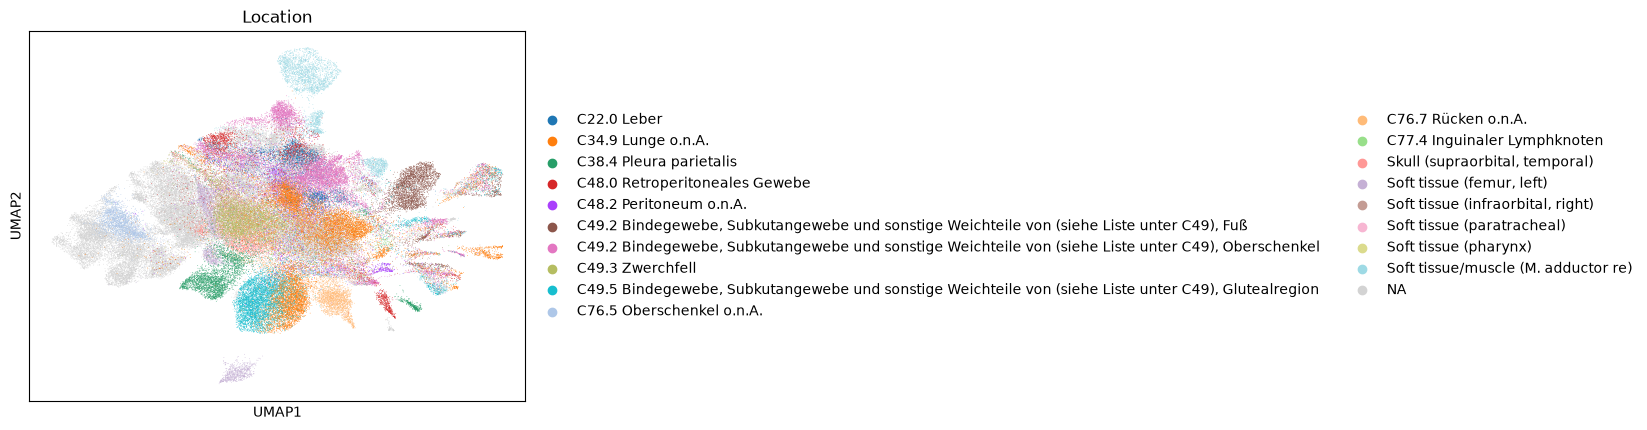

In [ ]:
sc.pl.umap(adata, color="Entity")
sc.pl.umap(adata, color="Cohort")
sc.pl.umap(adata, color="Fusion")
sc.pl.umap(adata, color="celltype")
sc.pl.umap(adata, color="Location")

pool


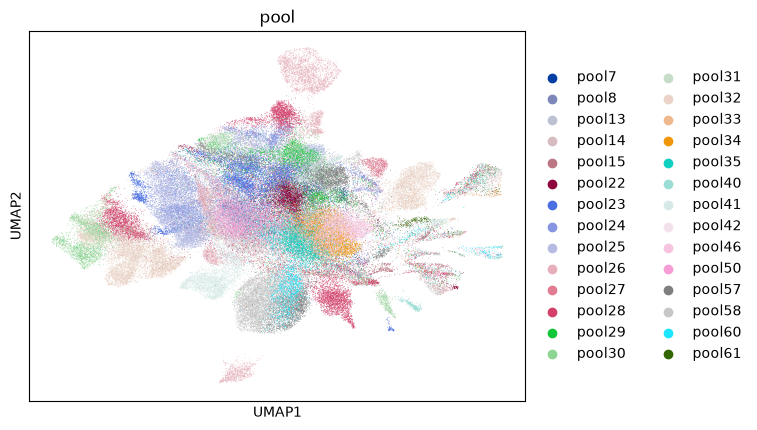

assignment


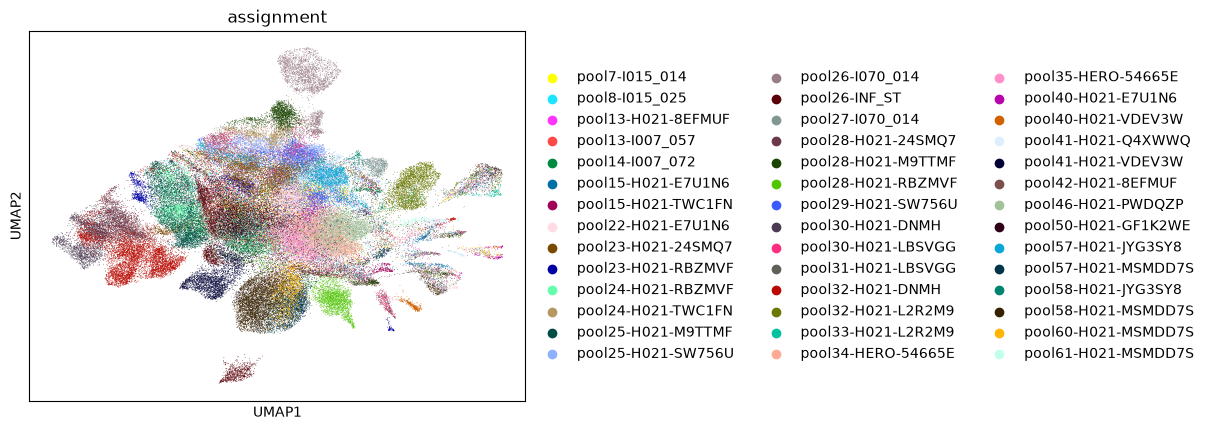

celltype


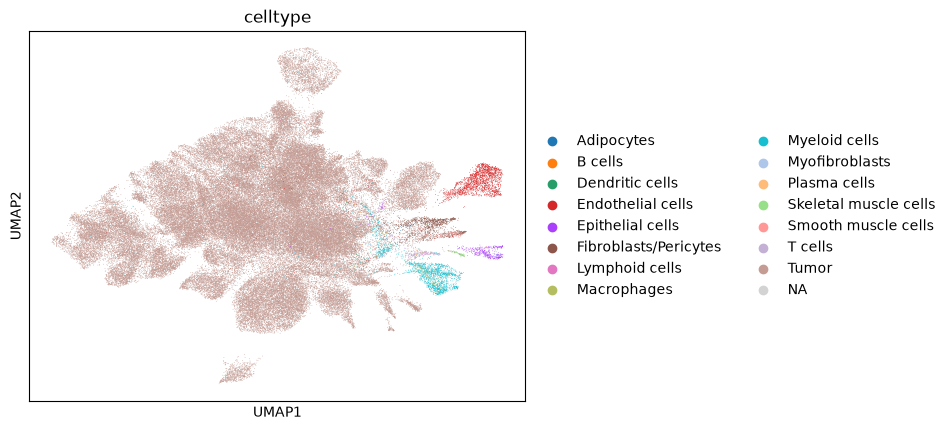

seurat_clusters


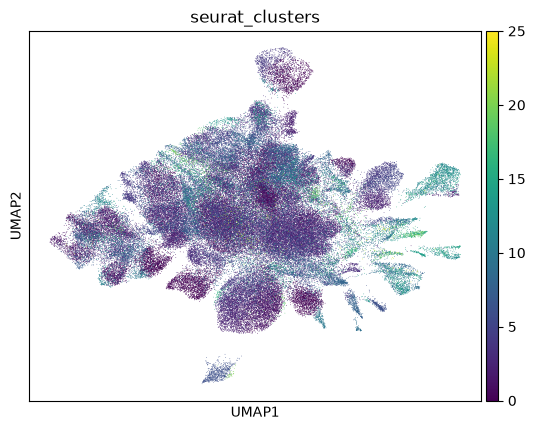

Cohort


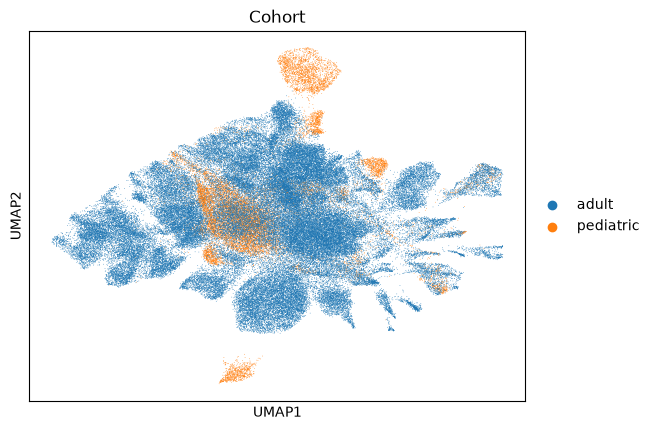

Entity


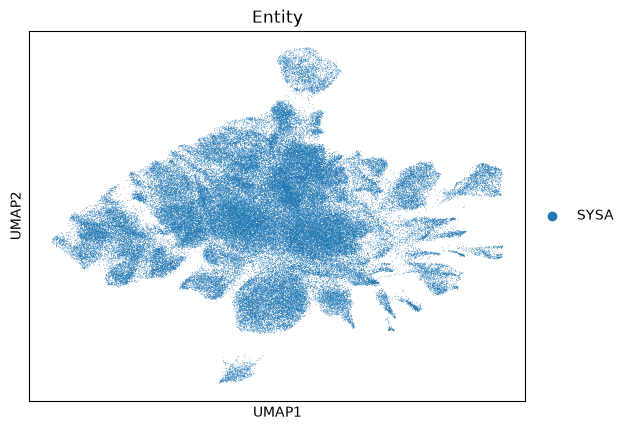

Fusion


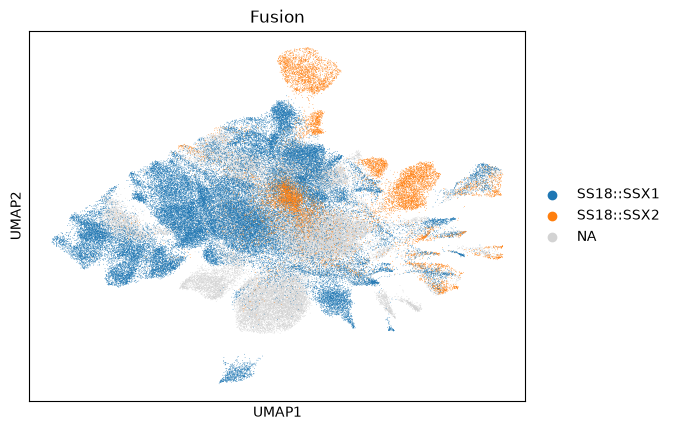

Episode


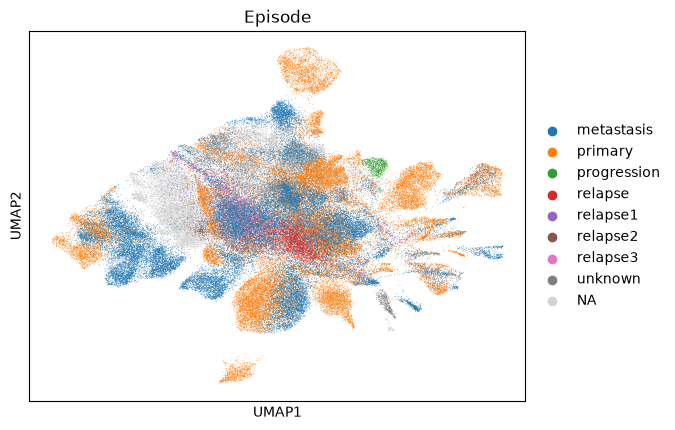

PID


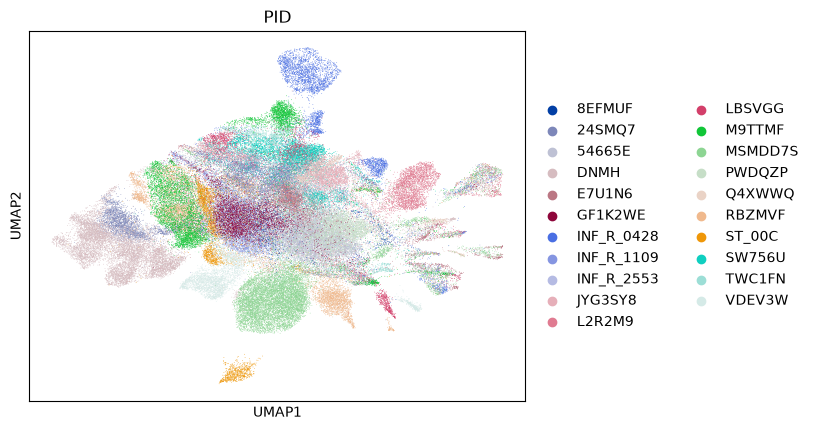

Location


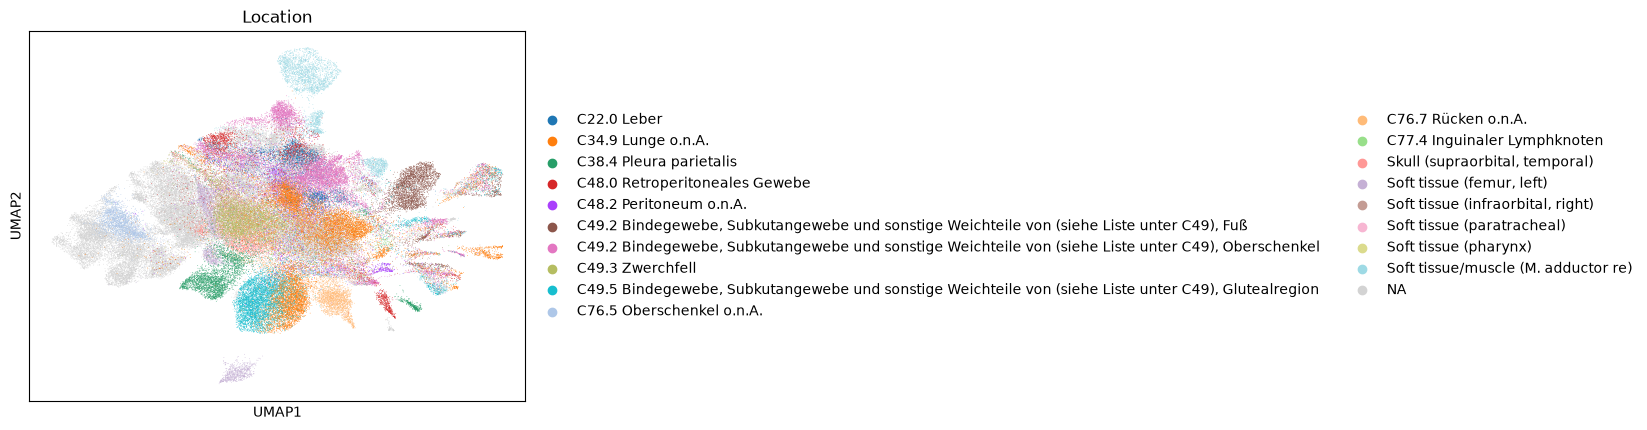

barcode_sample
n_genes


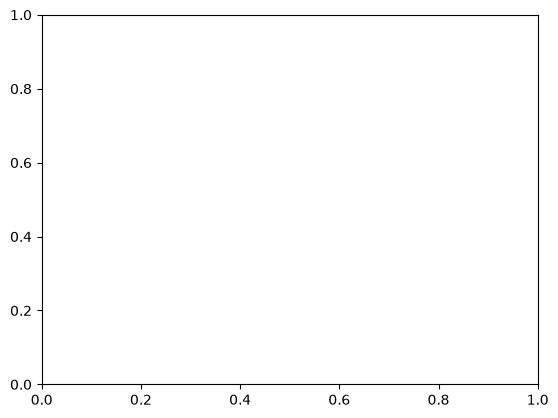

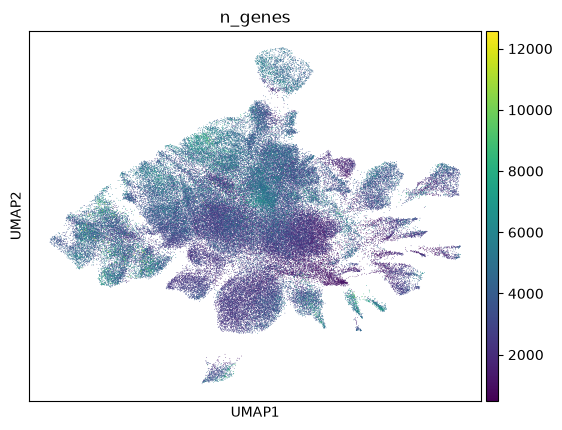

n_genes_by_counts


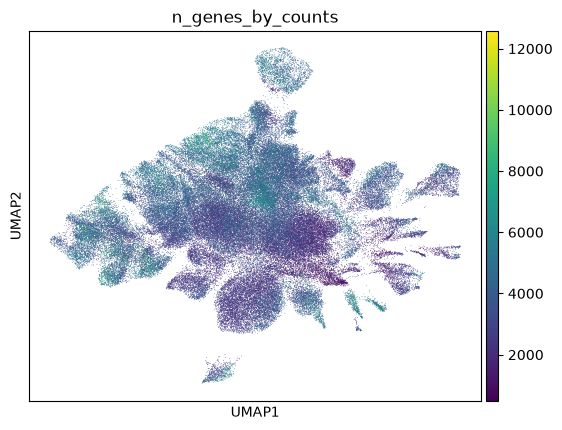

total_counts


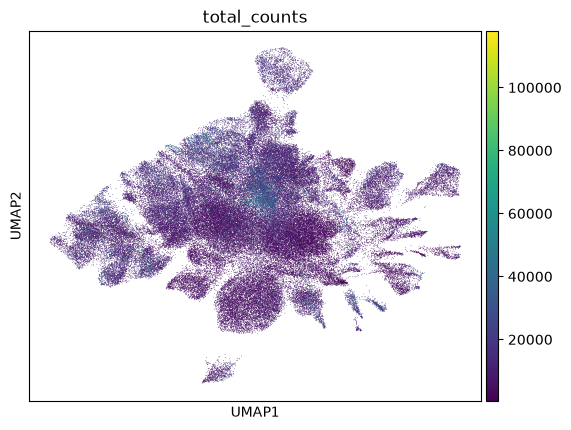

total_counts_mt


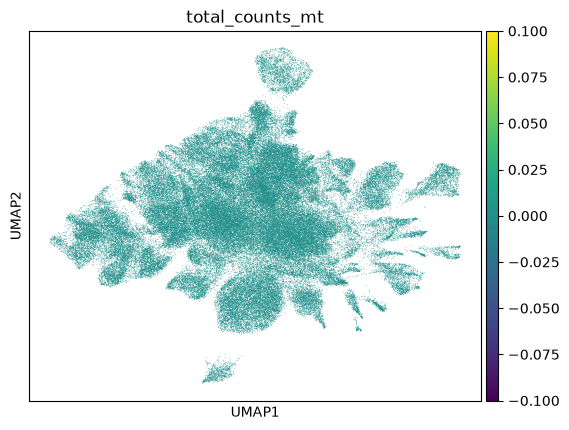

pct_counts_mt


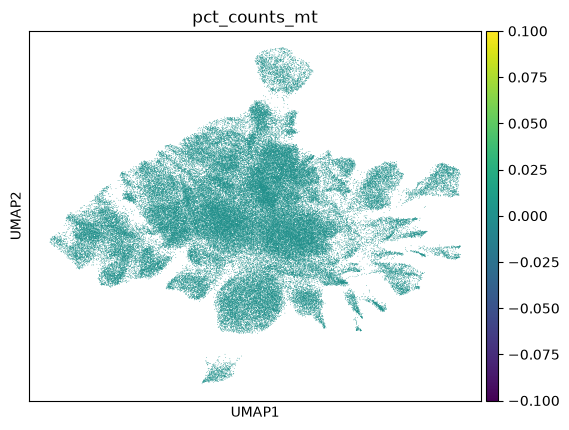

_scvi_batch


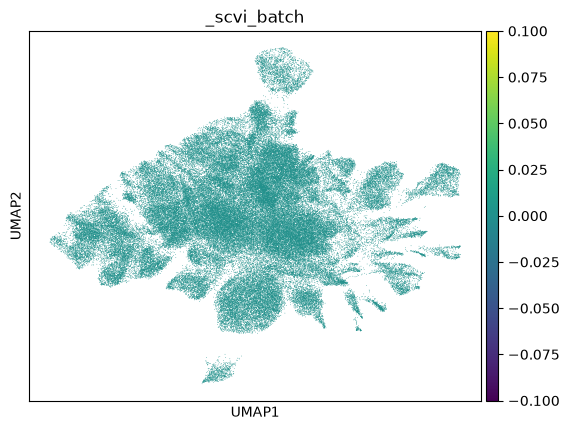

_scvi_labels


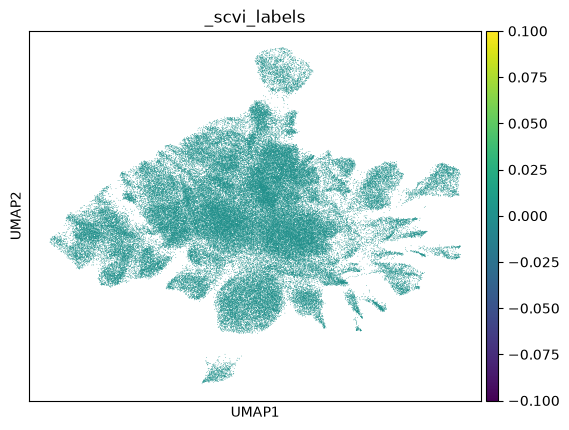

leiden


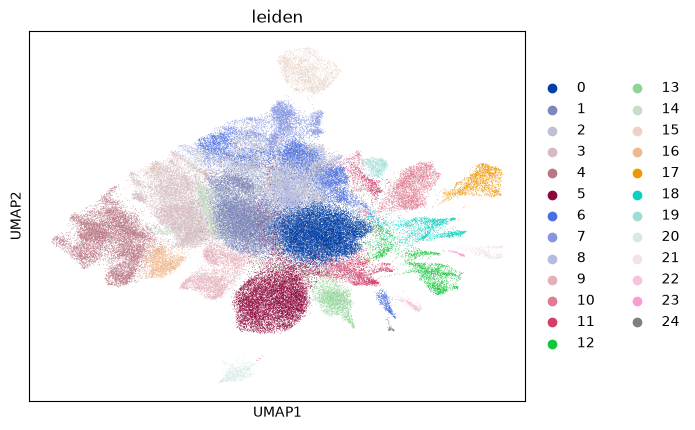

cytetype_annotation_leiden


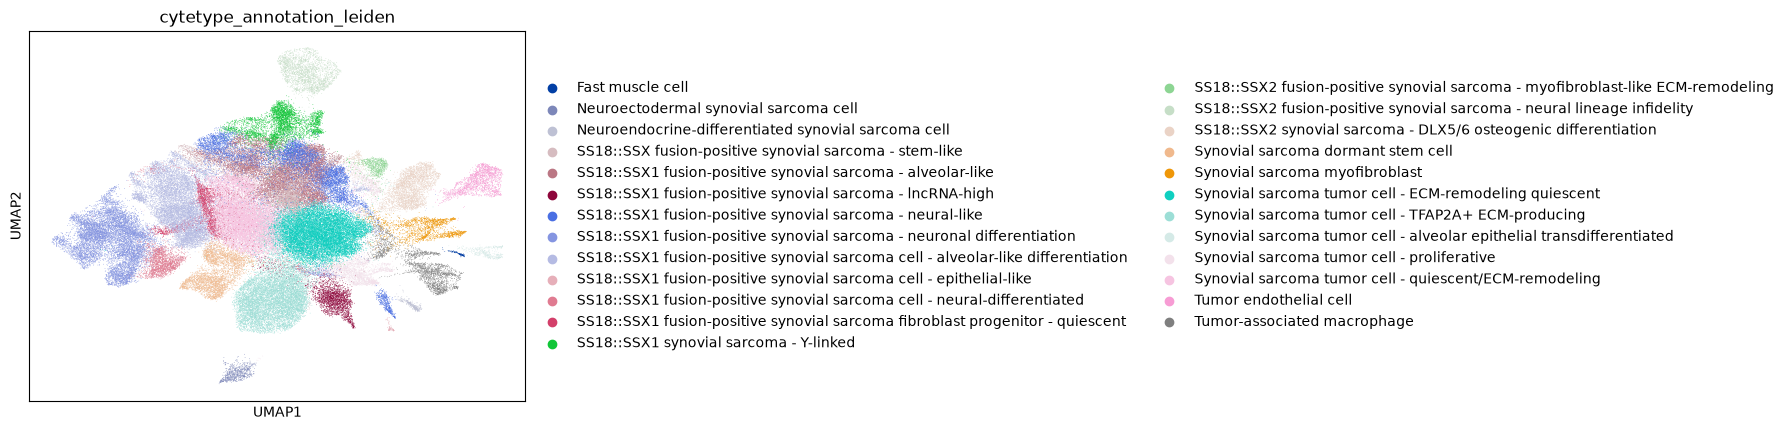

cytetype_cellOntologyTerm_leiden


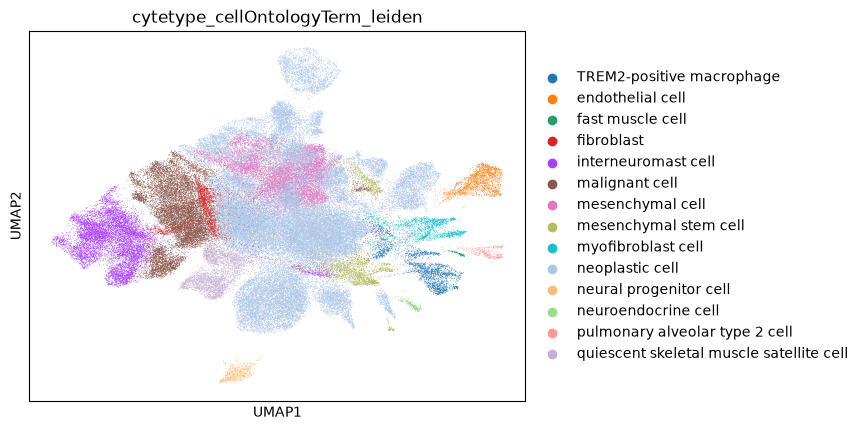

cytetype_cellOntologyTermID_leiden


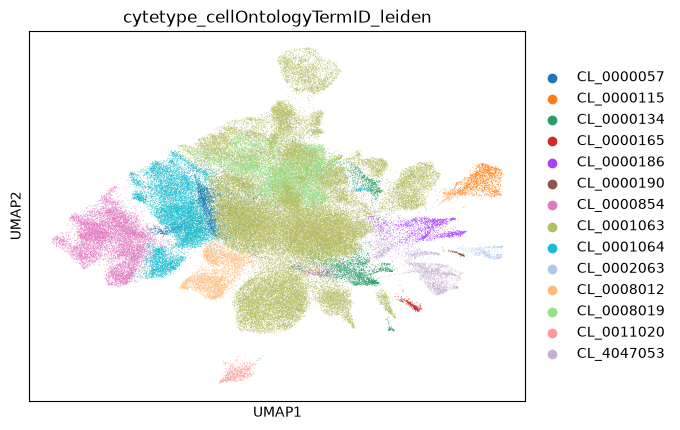

cytetype_cellState_leiden


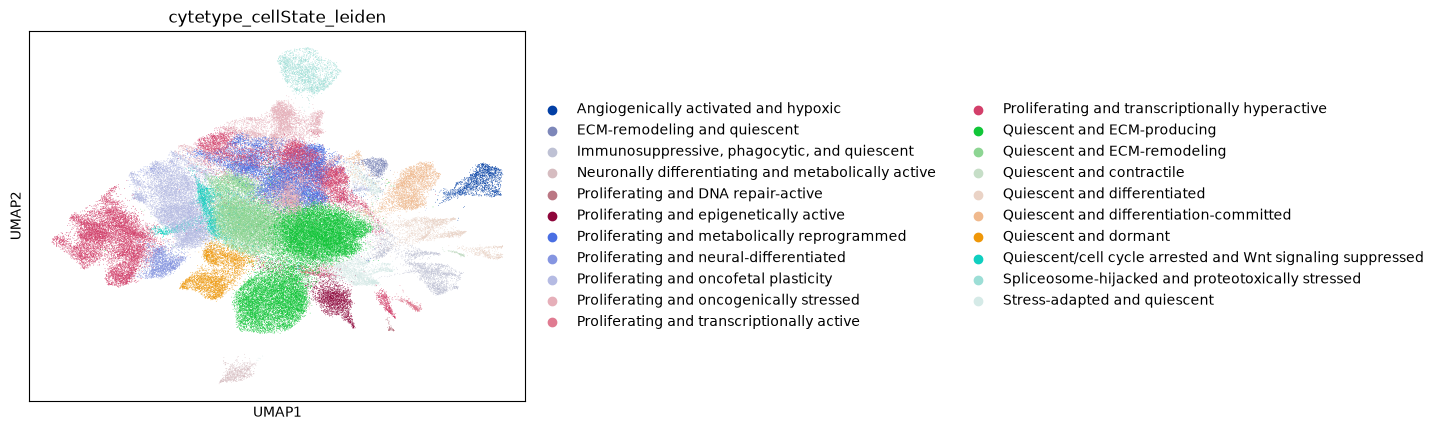

In [ ]:
for col in adata.obs.columns:
    print(col)
    try:
        sc.pl.umap(adata, color=str(col))
    except Exception as err:
        import traceback
        

## Data

In [ ]:
adata.raw.X.data.max(), adata.X.data.max(), adata.layers["counts"].data.max(),  adata.layers["scvi_normalized"].max()

(np.float32(7.792282),
 np.float32(7.792282),
 np.float32(4486.0),
 np.float32(480.51596))

In [ ]:
scvi_normalized=adata.layers["scvi_normalized"].flatten()

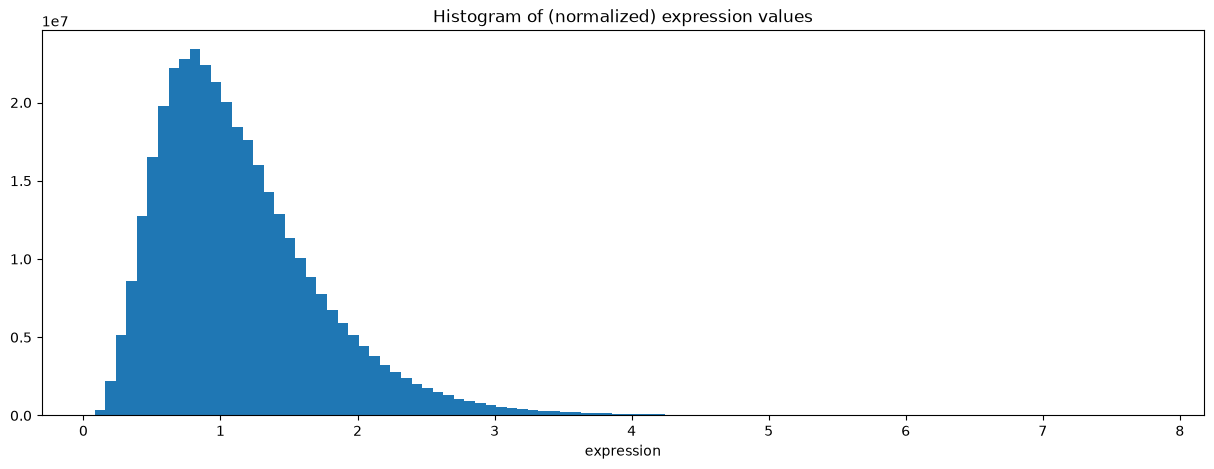

In [ ]:
from matplotlib.ticker import MultipleLocator
plt.figure(figsize=(15,5))
plt.hist(adata.X.data, bins=100)
plt.xlabel('expression')
plt.title('Histogram of (normalized) expression values')
plt.show()

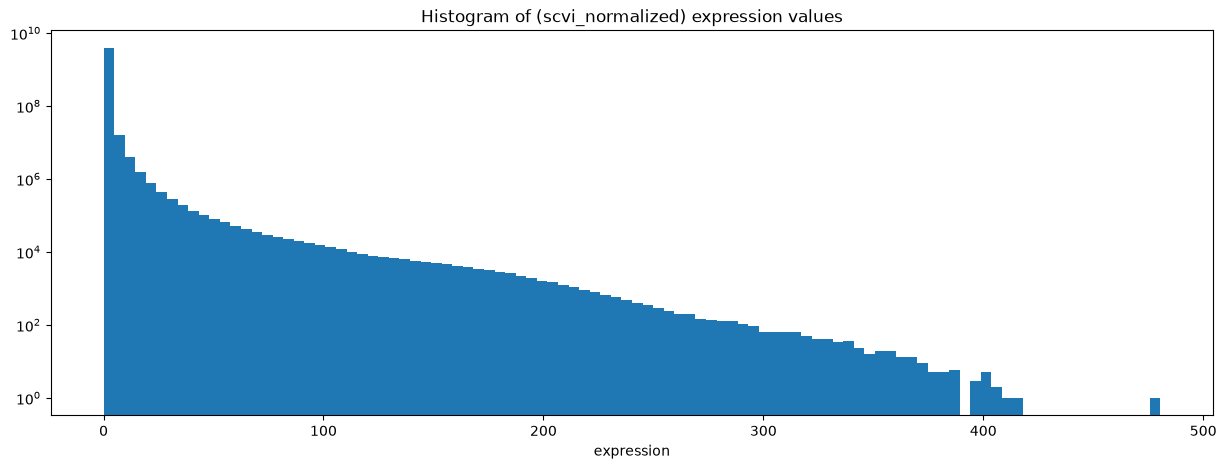

In [ ]:
from matplotlib.ticker import MultipleLocator
plt.figure(figsize=(15,5))
plt.hist(scvi_normalized, bins=100)
plt.xlabel('expression')
plt.title('Histogram of (scvi_normalized) expression values')
plt.yscale("log")
plt.show()

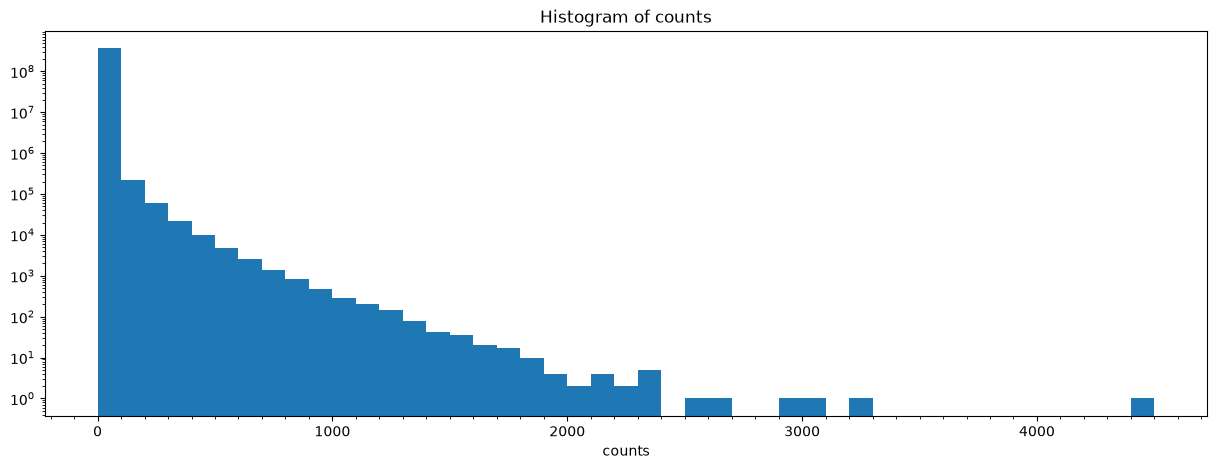

In [ ]:
from matplotlib.ticker import MultipleLocator
bin_edges = np.arange(0, adata.layers["counts"].data.max()+100, 100)

plt.figure(figsize=(15,5))
plt.hist(adata.layers["counts"].data, bins=bin_edges)
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(1000))
ax.xaxis.set_minor_locator(MultipleLocator(100))
plt.xlabel('counts')
plt.title('Histogram of counts')
plt.yscale("log")
plt.show()